## Business Insights and Strategic Recommendations

### Objective

The purpose of this notebook is to translate the analytical findings into meaningful business insights and actionable recommendations.

The focus is on understanding vehicle sales patterns, identifying high-performing segments, and providing strategic recommendations based on the results of the exploratory analysis and regression modeling.

#### Loading Data first

In [1]:
# Import necessary libraries 
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load cleaned dataset
df = pd.read_csv("../data/processed/car_sales_clean.csv")

# Restore important data types
df["Latest_Launch"] = pd.to_datetime(df["Latest_Launch"])

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.head()

,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,Acura,Integra,16.919,16.360,Passenger,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2012-02-02,58.280150
1,Acura,TL,39.384,19.875,Passenger,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,2011-06-03,91.370778
2,Acura,CL,14.114,18.225,Passenger,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,2012-01-04,72.030917
3,Acura,RL,8.588,29.725,Passenger,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2011-03-10,91.389779
4,Audi,A4,20.397,22.255,Passenger,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,2011-10-08,62.777639


#### 2. Price Segmentation Analysis

Vehicle pricing plays an important role in sales performance.

To better understand customer purchasing behavior, vehicles are divided into three price segments:

- Budget
- Mid-Range
- Premium

This analysis helps identify which price segment generates the highest average sales.

In [2]:
# Create price segments

df["Price_Category"] = pd.cut(
    df["Price_in_thousands"],
    bins=[0, 20, 40, 100],
    labels=["Budget", "Mid-Range", "Premium"]
)

# Check distribution

df["Price_Category"].value_counts()

Price_Category
Mid-Range    78
Budget       55
Premium      24
Name: count, dtype: int64

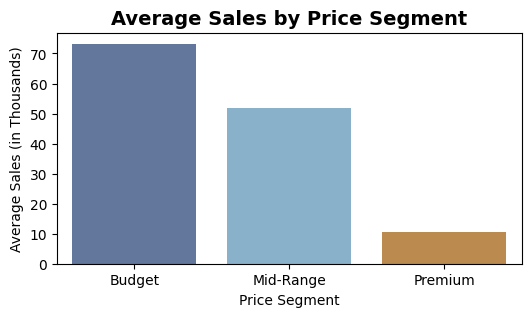

In [4]:
# Average sales by price category

sales_by_price = (
    df.groupby("Price_Category", observed=False)["Sales_in_thousands"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(6, 3))

sns.barplot(
    x=sales_by_price.index,
    y=sales_by_price.values,
    hue=sales_by_price.index,
    palette=["#5875A4", "#7FB3D5", "#CC8C3C"],
    legend=False
)

plt.title(
    "Average Sales by Price Segment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Price Segment")
plt.ylabel("Average Sales (in Thousands)")

plt.show()

#### Business Insight

Customers are more likely to purchase affordable vehicles, resulting in higher sales for the Budget segment. Premium vehicles, although higher in value, attract a smaller customer base and therefore achieve lower sales volumes.

#### 2. Manufacturer Positioning Analysis

Manufacturers differ in their pricing and sales strategies.

This analysis compares average vehicle price and total sales across manufacturers to identify whether brands compete through high sales volumes or premium pricing.


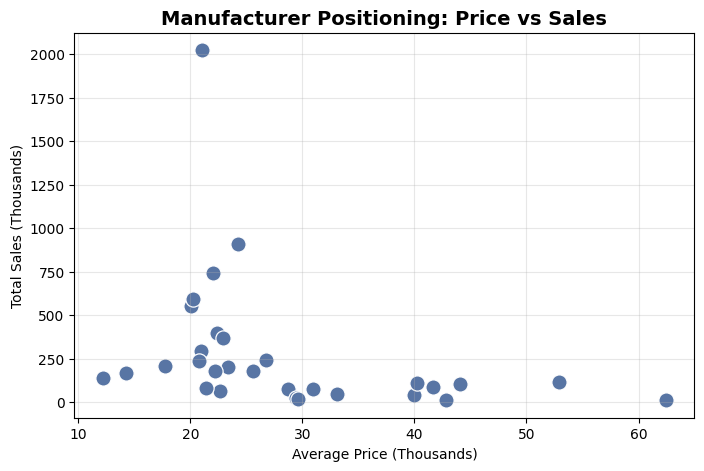

In [6]:
manufacturer_summary = (
    df.groupby("Manufacturer", observed=False)
      .agg(
          Average_Price=("Price_in_thousands", "mean"),
          Total_Sales=("Sales_in_thousands", "sum")
      )
      .reset_index()
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=manufacturer_summary,
    x="Average_Price",
    y="Total_Sales",
    color="#5875A4",
    s=120
)

plt.title(
    "Manufacturer Positioning: Price vs Sales",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average Price (Thousands)")
plt.ylabel("Total Sales (Thousands)")

plt.grid(alpha=0.3)

plt.show()